In [2]:
!pip install -q transformers datasets accelerate scikit-learn

In [3]:
import numpy as np
import pandas as pd

base = "https://raw.githubusercontent.com/Husnainhassan11/roman-urdu-sentiment-analysis/main/Data/"
train_df = pd.read_csv(base + "train.csv")
val_df = pd.read_csv(base + "val.csv")
print(len(train_df), len(val_df))

labels = ["Negative", "Neutral", "Positive"]
label2id = {l: i for i, l in enumerate(labels)}
id2label = {i: l for l, i in label2id.items()}
for d in (train_df, val_df):
    d["labels"] = d["label"].map(label2id)

15596 1949


In [4]:
from datasets import Dataset
from transformers import AutoTokenizer

checkpoint = "xlm-roberta-base"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

def tokenize(batch):
    return tokenizer(batch["sentence"], truncation=True, max_length=128)

def to_dataset(d):
    ds = Dataset.from_pandas(d[["sentence", "labels"]].reset_index(drop=True))
    return ds.map(tokenize, batched=True)

train_ds, val_ds = to_dataset(train_df), to_dataset(val_df)

lengths = [len(x) for x in train_ds["input_ids"]]
print("Token length percentiles (50, 90, 95, 99):", np.percentile(lengths, [50, 90, 95, 99]))

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Map:   0%|          | 0/15596 [00:00<?, ? examples/s]

Map:   0%|          | 0/1949 [00:00<?, ? examples/s]

Token length percentiles (50, 90, 95, 99): [ 17.  44.  60. 100.]


In [5]:
import torch
from transformers import (AutoModelForSequenceClassification, TrainingArguments,
                          Trainer, DataCollatorWithPadding)
from sklearn.metrics import accuracy_score, f1_score

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE")

model = AutoModelForSequenceClassification.from_pretrained(
    checkpoint, num_labels=3, id2label=id2label, label2id=label2id)

def compute_metrics(eval_pred):
    logits, y_true = eval_pred
    y_pred = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, average="macro")}

args = TrainingArguments(
    output_dir="xlmr-roman-urdu",
    learning_rate=2e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    num_train_epochs=3,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    fp16=True,
    seed=42,
    report_to="none",
)

trainer = Trainer(
    model=model, args=args,
    train_dataset=train_ds, eval_dataset=val_ds,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
)
trainer.train()

GPU: Tesla T4


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,No log,0.871450,0.612109,0.600459
2,0.977496,0.835496,0.632119,0.605446
3,0.845351,0.806121,0.653155,0.645034


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1464, training_loss=0.8634923090700244, metrics={'train_runtime': 513.1169, 'train_samples_per_second': 91.184, 'train_steps_per_second': 2.853, 'total_flos': 2012018027498136.0, 'train_loss': 0.8634923090700244, 'epoch': 3.0})

              precision    recall  f1-score   support

    Negative      0.595     0.598     0.597       523
     Neutral      0.709     0.686     0.698       845
    Positive      0.628     0.654     0.641       581

    accuracy                          0.653      1949
   macro avg      0.644     0.646     0.645      1949
weighted avg      0.654     0.653     0.654      1949



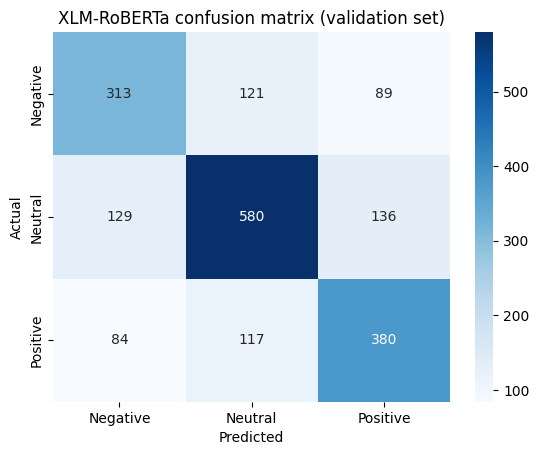

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

out = trainer.predict(val_ds)
y_pred = out.predictions.argmax(-1)
y_true = out.label_ids

print(classification_report(y_true, y_pred, target_names=labels, digits=3))

cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title("XLM-RoBERTa confusion matrix (validation set)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [7]:
probs = torch.softmax(torch.tensor(out.predictions), dim=-1).numpy()
view = val_df.reset_index(drop=True).copy()
view["pred"] = [id2label[i] for i in y_pred]
view["confidence"] = probs.max(axis=1).round(2)

wrong = view[view["pred"] != view["label"]]
print("Wrong:", len(wrong), "of", len(view))
wrong.sort_values("confidence", ascending=False).head(15)[["sentence", "label", "pred", "confidence"]]

Wrong: 676 of 1949


,sentence,label,pred,confidence
1740,True ...Allah hum sub ko hidayat aur taufeek d...,Neutral,Positive,0.96
1395,Allah hum hadyat de,Negative,Positive,0.96
818,"THANKS, I PRAY TO ALMIGHTY ALLAH THAT HE MAY H...",Neutral,Positive,0.96
555,Beshak\nWaalaikumAssalam\nApp Sab ko bhi jumma...,Neutral,Positive,0.96
545,Beshak syed zada,Neutral,Positive,0.96
1544,somebody tell me why?,Negative,Neutral,0.95
97,Hame bad dua lagi ha kaiswar ki,Negative,Positive,0.95
187,May allah give you a long life....Rajb tayyab ...,Neutral,Positive,0.95
767,Well done hahaha,Negative,Neutral,0.95
531,uncle aunty ka num de,Positive,Neutral,0.95


In [8]:
from transformers import pipeline

clf = pipeline("text-classification", model=trainer.model, tokenizer=tokenizer, device=0)
clf(["bohat acha product hai", "bakwas service, paise zaya", "kal delivery aa jaye gi"])

[{'label': 'Positive', 'score': 0.9526111483573914},
 {'label': 'Neutral', 'score': 0.5518686175346375},
 {'label': 'Neutral', 'score': 0.923787534236908}]

In [10]:
from huggingface_hub import notebook_login
notebook_login()    # paste the token in the box that appears

In [11]:
trainer.model.push_to_hub("roman-urdu-sentiment-xlmr")
tokenizer.push_to_hub("roman-urdu-sentiment-xlmr")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...2zogig_/model.safetensors:   0%|          | 13.5kB / 1.11GB            

Validating                    :           |   0%            

README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...mpupwrk6_6/tokenizer.json: 100%|##########| 17.1MB / 17.1MB            

Validating                    :           |   0%            

CommitInfo(commit_url='https://huggingface.co/husnainhassan/roman-urdu-sentiment-xlmr/commit/943261cf717196e6358df90f7289541d4d6c2b11', commit_message='Upload tokenizer', commit_description='', oid='943261cf717196e6358df90f7289541d4d6c2b11', pr_url=None, repo_url=RepoUrl('https://huggingface.co/husnainhassan/roman-urdu-sentiment-xlmr', endpoint='https://huggingface.co', repo_type='model', repo_id='husnainhassan/roman-urdu-sentiment-xlmr'), pr_revision=None, pr_num=None)